# Herding with Q-learning
##### *Bonus practical: reinforcement learning agents in an agent-based model*

#### **The herding task**
We have a field (a grid) with a pen in the top-right corner. There is a sheep, and there are one or two dogs. The goal is to get the sheep into the pen.

The **sheep** is a classic rule-based agent, like the agents you have built in this course. If a dog comes close (within the *flee radius*), the sheep moves away from it. If no dog is close, the sheep mostly grazes and sometimes wanders a bit.

The **dogs** are different. They have no rules for herding. They have to *learn* what to do from reward alone. Every step costs a little (-0.1), and getting the sheep into the pen gives a big reward (+10). The dogs learn with **Q-learning**.

#### **Q-learning in one line**
Each dog keeps a table Q(s, a): how much reward it expects in the long run if it does action *a* in state *s*. After every step the dog compares what it expected with what it actually got. This is the **TD error** (temporal difference error):

\begin{equation}
\delta = r + \gamma \max_{a'} Q(s', a') - Q(s, a)
\end{equation}

So: the reward we just got (*r*), plus what we now expect from the next state (discounted by $\gamma$), minus what we expected before. If $\delta$ is positive, things went better than expected; if negative, worse. The dog then nudges its expectation a bit (learning rate $\alpha$) in that direction:

\begin{equation}
Q(s, a) \leftarrow Q(s, a) + \alpha \, \delta
\end{equation}

The dog mostly picks the action with the highest Q value, but with probability $\epsilon$ it does something random (exploration).

#### **What does a dog see?**
A dog's state *s* is: the position of the sheep on the field (x, y), and where the sheep is relative to the dog (dx, dy, cut off at 3 cells). Importantly, **a dog does not see the other dog**. For each dog, the other dog is just part of its environment.

#### **The stubborn sheep**
The sheep has a parameter `dogs_needed`. With `dogs_needed = 1` the sheep flees from any dog. With `dogs_needed = 2` the sheep is stubborn: it only moves away when *two* dogs are close at the same time. One dog alone can then never herd it.

So remember we have the following components:
* Number of dogs (1 or 2)
* Dogs needed to move the sheep (1 or 2)
* Learning rate $\alpha$, discount $\gamma$, exploration $\epsilon$
* Flee radius of the sheep
* Number of training steps

# Lets get started

In [1]:
import mesa
from mesa.discrete_space import OrthogonalMooreGrid, CellAgent
from mesa.visualization import SolaraViz
import solara
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import deque
import copy

# the five things an agent can do: stay, right, left, up, down
ACTIONS = [(0, 0), (1, 0), (-1, 0), (0, 1), (0, -1)]

# Agent setup: the sheep (rule-based)

In [2]:
class Sheep(CellAgent):
    """A rule-based sheep that flees from dogs.
    flee_radius: how close a dog must be before the sheep reacts
    dogs_needed: how many dogs must be close before the sheep moves away (1 = normal sheep, 2 = stubborn sheep)
    """
    def __init__(self, model, cell, flee_radius=2, dogs_needed=1):
        super().__init__(model)
        self.cell = cell
        self.flee_radius = flee_radius
        self.dogs_needed = dogs_needed

    def distance_to_nearest_dog(self, position):
        dog_positions = [dog.cell.coordinate for dog in self.model.agents_by_type[Dog]]
        return min(max(abs(position[0] - dx), abs(position[1] - dy)) for dx, dy in dog_positions)

    def step(self):
        x, y = self.cell.coordinate
        # where could the sheep go (staying inside the field)?
        options = [(x + ax, y + ay) for ax, ay in ACTIONS if self.model.inside((x + ax, y + ay))]
        # how many dogs are close?
        dogs_close = sum(max(abs(x - d.cell.coordinate[0]), abs(y - d.cell.coordinate[1])) <= self.flee_radius
                         for d in self.model.agents_by_type[Dog])

        if dogs_close >= self.dogs_needed:
            # flee: pick the option(s) furthest away from the nearest dog
            best = max(self.distance_to_nearest_dog(p) for p in options)
            options = [p for p in options if self.distance_to_nearest_dog(p) == best]
        elif dogs_close > 0 or self.model.random.random() > 0.2:
            # a dog is close but not enough dogs to impress us, or we just graze: stay put
            options = [(x, y)]
        # otherwise (20% of the time when no dog is near) wander randomly

        self.cell = self.model.grid[self.model.random.choice(options)]

# Agent setup: the dog (Q-learning)
The key method is `learn()`. This is where the TD error is computed and the Q-table is updated. That is really all there is to Q-learning.

In [3]:
class Dog(CellAgent):
    """A dog that learns to herd with Q-learning.
    alpha: learning rate (how much do we update after a surprise)
    gamma: discount (how much do we care about future reward)
    epsilon: exploration (how often do we do something random)
    """
    def __init__(self, model, cell, alpha=0.1, gamma=0.95, epsilon=0.1):
        super().__init__(model)
        self.cell = cell
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.learning = True  # we can switch learning off (e.g., to freeze a trained dog)
        self.Q = {}           # the Q-table: state -> one value per action

    def observe(self):
        """The state: where is the sheep, and where is the sheep relative to me?"""
        sx, sy = self.model.sheep.cell.coordinate
        x, y = self.cell.coordinate
        return (sx, sy, int(np.clip(sx - x, -3, 3)), int(np.clip(sy - y, -3, 3)))

    def q_values(self, state):
        if state not in self.Q:  # never seen this state? then we expect nothing yet
            self.Q[state] = np.zeros(len(ACTIONS))
        return self.Q[state]

    def act(self):
        """Pick an action (epsilon-greedy) and move."""
        self.state = self.observe()
        if self.model.random.random() < self.epsilon:
            self.action = self.model.random.randrange(len(ACTIONS))  # explore
        else:
            q = self.q_values(self.state)  # exploit: best action (random among ties)
            self.action = self.model.random.choice(np.flatnonzero(q == q.max()).tolist())
        x, y = self.cell.coordinate
        new_position = (x + ACTIONS[self.action][0], y + ACTIONS[self.action][1])
        if self.model.inside(new_position):
            self.cell = self.model.grid[new_position]

    def learn(self, reward, done):
        """Q-learning update: compute the TD error and nudge Q(s, a)."""
        if not self.learning:
            return
        if done:
            target = reward  # the episode is over, there is no future
        else:
            target = reward + self.gamma * self.q_values(self.observe()).max()
        td_error = target - self.q_values(self.state)[self.action]
        self.q_values(self.state)[self.action] += self.alpha * td_error

# Model setup
One model step is: the dogs act, the sheep reacts, and then the dogs learn from what happened. An **episode** ends when the sheep is in the pen (or after `max_steps`). Then the sheep and dogs are placed somewhere random again, but the dogs keep their Q-tables. So over many episodes the dogs get better.

The datacollector collects data at the end of every episode (not every step).

In [4]:
class HerdingModel(mesa.Model):
    def __init__(self, n_dogs=1, dogs_needed=1, size=8, pen_size=2, max_steps=200,
                 flee_radius=2, alpha=0.1, gamma=0.95, epsilon=0.1, rng=None):
        super().__init__(rng=rng)
        self.size = size
        self.pen_size = pen_size
        self.max_steps = max_steps  # max steps per episode
        self.grid = OrthogonalMooreGrid((size, size), torus=False, random=self.random)

        self.sheep = Sheep(self, self.random_cell(), flee_radius=flee_radius, dogs_needed=dogs_needed)
        Dog.create_agents(self, n_dogs, [self.random_cell() for _ in range(n_dogs)],
                          alpha=alpha, gamma=gamma, epsilon=epsilon)

        self.t = 0                 # step within the current episode
        self.episode = 0
        self.last_episode_length = 0
        self.last_success = False
        self.recent = deque(maxlen=200)  # (success, length) of the last 200 episodes
        self.datacollector = mesa.DataCollector(
            model_reporters={
                "episode": "episode",
                "episode_length": "last_episode_length",
                "success": "last_success",
                "recent_success_rate": lambda m: np.mean([s for s, l in m.recent]) if m.recent else 0,
                "recent_episode_length": lambda m: np.mean([l for s, l in m.recent]) if m.recent else 0,
            }
        )

    def inside(self, position):
        return 0 <= position[0] < self.size and 0 <= position[1] < self.size

    def in_pen(self, position):
        return position[0] >= self.size - self.pen_size and position[1] >= self.size - self.pen_size

    def random_cell(self):
        """A random cell that is not in the pen."""
        while True:
            position = (self.random.randrange(self.size), self.random.randrange(self.size))
            if not self.in_pen(position):
                return self.grid[position]

    def new_episode(self, success):
        self.last_episode_length = self.t
        self.last_success = success
        self.recent.append((success, self.t))
        self.episode += 1
        self.datacollector.collect(self)
        self.t = 0
        self.sheep.cell = self.random_cell()
        for dog in self.agents_by_type[Dog]:
            dog.cell = self.random_cell()

    def step(self):
        dogs = self.agents_by_type[Dog]
        dogs.do("act")
        self.sheep.step()
        self.t += 1

        done = self.in_pen(self.sheep.cell.coordinate)
        reward = 10.0 if done else -0.1   # shared reward: every dog gets the same
        dogs.do("learn", reward, done)

        if done or self.t >= self.max_steps:
            self.new_episode(success=done)

# Lets train some dogs
We train four set-ups for 300,000 steps each and look at the learning curves: how long does it take the dogs to pen the sheep, episode after episode? (This takes about two minutes.)

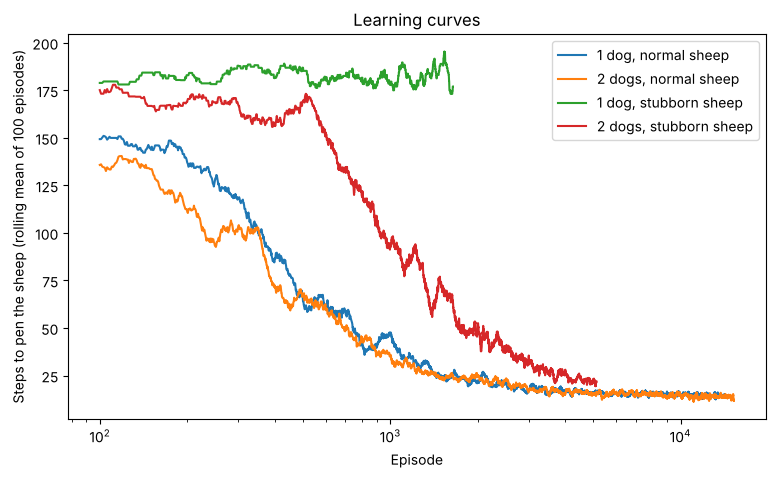

In [5]:
def train(n_steps=300_000, **params):
    model = HerdingModel(**params)
    for _ in range(n_steps):
        model.step()
    return model

conditions = {
    "1 dog, normal sheep":    dict(n_dogs=1, dogs_needed=1),
    "2 dogs, normal sheep":   dict(n_dogs=2, dogs_needed=1),
    "1 dog, stubborn sheep":  dict(n_dogs=1, dogs_needed=2),
    "2 dogs, stubborn sheep": dict(n_dogs=2, dogs_needed=2),
}
trained = {name: train(rng=1, **params) for name, params in conditions.items()}

fig, ax = plt.subplots(figsize=(9, 5))
for name, model in trained.items():
    df = model.datacollector.get_model_vars_dataframe()
    ax.plot(df["episode"], df["episode_length"].rolling(100).mean(), label=name)
ax.set_xscale("log")  # log scale, because the good dogs do many (short) episodes
ax.set_xlabel("Episode")
ax.set_ylabel("Steps to pen the sheep (rolling mean of 100 episodes)")
ax.set_title("Learning curves")
ax.legend()
plt.show()

# Make a custom visualization so we can watch the trained dogs
We pass a *trained* model to SolaraViz, so press play (not reset: reset makes a new, untrained model). We set exploration low (5%) so we mostly see what the dogs have actually learned. (With exploration at exactly 0 the dogs sometimes get stuck in a loop, try it.)

In [6]:
from matplotlib.patches import Rectangle

@solara.component
def HerdingVisualization(model):
    from mesa.visualization.components.matplotlib_components import update_counter
    update_counter.get()  # re-render when the model steps
    fig = plt.Figure(figsize=(6, 6))
    ax = fig.subplots()
    s, p = model.size, model.pen_size
    ax.add_patch(Rectangle((0, 0), s, s, facecolor="yellowgreen", alpha=0.3))          # the field
    ax.add_patch(Rectangle((s - p, s - p), p, p, facecolor="saddlebrown", alpha=0.4))  # the pen
    x, y = model.sheep.cell.coordinate
    ax.scatter(x + 0.5, y + 0.5, s=600, c="white", edgecolors="black", zorder=10)
    for i, dog in enumerate(model.agents_by_type[Dog]):
        dx, dy = dog.cell.coordinate
        ax.scatter(dx + 0.5, dy + 0.5, s=300, c=["black", "tab:orange"][i % 2], marker="s", zorder=10)
    ax.set_xlim(0, s)
    ax.set_ylim(0, s)
    ax.set_aspect("equal")
    ax.set_xticks(range(s + 1))
    ax.set_yticks(range(s + 1))
    ax.grid(True, alpha=0.3)
    ax.set_title(f"Episode {model.episode}, step {model.t}")
    solara.FigureMatplotlib(fig)

model = trained["2 dogs, stubborn sheep"]   # try the other conditions too
for dog in model.agents_by_type[Dog]:
    dog.epsilon = 0.05

page = SolaraViz(model, components=[HerdingVisualization], name="Herding with Q-learning")
page

Cannot show ipywidgets in text

# Batch run
Now we do it properly, over several seeds. For each condition we look at the end of training: over the last 200 episodes, how often do the dogs succeed, and how many steps do they need? (This takes a few minutes.)

  0%|          | 0/8 [00:00<?, ?it/s]

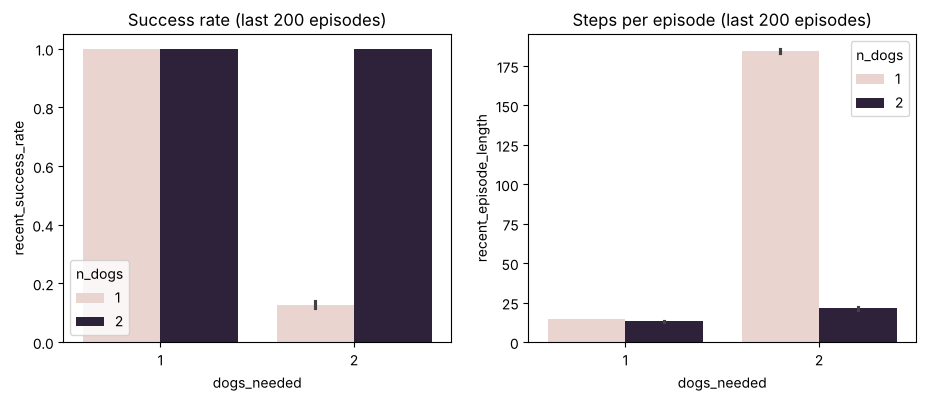

In [7]:
params = {"n_dogs": [1, 2],
          "dogs_needed": [1, 2]}

results = mesa.batch_run(
    HerdingModel,
    parameters=params,
    rng=[1, 2],               # two seeds per condition
    max_steps=300_000,
    number_processes=1,
    data_collection_period=-1,  # only collect at the end of the run
    display_progress=True,
)
results = pd.DataFrame(results)
results.to_csv("./herding_batch_run.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(results, x="dogs_needed", y="recent_success_rate", hue="n_dogs", ax=axes[0])
sns.barplot(results, x="dogs_needed", y="recent_episode_length", hue="n_dogs", ax=axes[1])
axes[0].set_title("Success rate (last 200 episodes)")
axes[1].set_title("Steps per episode (last 200 episodes)")
plt.show()

# Partner swap
Here is a nice one. Take a trained dog from one run and pair it with a trained dog from a *different* run (different seed). Both dogs know how to herd a stubborn sheep, but did they learn the same way of working together? We freeze learning and exploration and just test them.

In [8]:
def test(model, n_episodes=300, epsilon=0.05):
    """Run a model with learning switched off, return the success rate."""
    for dog in model.agents_by_type[Dog]:
        dog.learning, dog.epsilon = False, epsilon
    start = model.episode
    while model.episode < start + n_episodes:
        model.step()
    df = model.datacollector.get_model_vars_dataframe()
    return df[df["episode"] > start]["success"].mean()

team_a = train(n_dogs=2, dogs_needed=2, rng=2)
team_b = train(n_dogs=2, dogs_needed=2, rng=3)
print("Team A together:", test(copy.deepcopy(team_a)))
print("Team B together:", test(copy.deepcopy(team_b)))

# new model with one dog from team A and one dog from team B
mixed = HerdingModel(n_dogs=2, dogs_needed=2, rng=9)
dog_new_1, dog_new_2 = list(mixed.agents_by_type[Dog])
dog_new_1.Q = list(team_a.agents_by_type[Dog])[0].Q
dog_new_2.Q = list(team_b.agents_by_type[Dog])[1].Q
print("Mixed team:     ", test(mixed))

Team A together: 0.98


Team B together: 0.9433333333333334


Mixed team:      0.75


# Experiments for you
1. **Why does a second dog not help with a normal sheep?** Look at the learning curves. Is the second dog useless, or is it in the way?
2. **One dog, stubborn sheep.** The dog never gets reward. What does it learn? (Hint: look at its Q-table, `dog.Q`.)
3. **Freeze a partner.** Train two dogs with a stubborn sheep, but switch off learning for one dog from the start (`dog.learning = False`, it then just explores randomly). Can one learner work with a partner that does not learn? Now first train one dog with a normal sheep, freeze it, and add a second learning dog with a stubborn sheep. Is learning faster when your partner is stable?
4. **Partner swap.** Does the mixed team do as well as the original teams? Try other seeds too (some pairs work fine, some do not). What does that tell you about *where* the coordination lives: in each dog, or in the pair?
5. **Learning parameters.** Change $\alpha$, $\gamma$ and $\epsilon$. What happens with $\gamma = 0$ (the dog only cares about the next step)? And with no exploration?
6. **Bigger field.** Try `size=12`. The Q-table gets much bigger. How does that affect learning time?
7. **Advanced: seeing your partner.** Change `observe()` so a dog also sees roughly where the other dog is (e.g., the sign of dx and dy). Does that help or hurt?